# 04 · ALS: матричная факторизация

У ItemKNN сходство зависит от общих зрителей. ALS позволяет описать пользователя и объект небольшими векторами скрытых факторов. Проверяю, поможет ли это найти связи, которых не хватает в прямом сравнении просмотров.

Сравниваю три конфигурации на Validation. Порог положительного просмотра и временные границы оставляю прежними; глубину просмотра в веса не перевожу.

## Импорты

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA_DIR = Path(os.environ.get("KION_DATA_DIR", ROOT / "data"))
REPORTS = ROOT / "reports" / "full"
K = 10
blas_limit = threadpool_limits(limits=1, user_api="blas")
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

In [2]:
from kion_recsys.als import ALSRecommender

## Матричная факторизация

Для матрицы взаимодействий $R$ модель строит два набора латентных векторов:

$$R \approx PQ^T, \qquad \hat r_{ui}=p_u^Tq_i.$$

Размерность латентных факторов задаёт параметр `factors`. Координаты не имеют заранее заданных семантических названий.

Скалярное произведение факторов задаёт порядок кандидатов. Позже использую эту оценку как один из признаков ранкера.

### Неявная обратная связь

Здесь $p_{ui}=1$ для положительного взаимодействия и $p_{ui}=0$ для ненаблюдавшейся пары. Наблюдаемым положительным взаимодействиям назначается уверенность $c_{ui}=1+\alpha$; ненаблюдавшимся — $c_{ui}=1$.

Модель оптимизирует взвешенную ошибку приближения:

$$\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right).$$

ALS попеременно оптимизирует пользовательские и объектные факторы. Параметр `regularization` управляет регуляризацией, `iterations` — количеством чередований, `factors` — размерностью векторов.

Так просмотренные объекты получают больший вес в функции потерь, чем остальные пары из матрицы.

## Данные

In [3]:
from kion_recsys.data import TrainingData, load_interactions, split_interactions
from kion_recsys.metrics import build_targets, ranking_metrics

interactions = load_interactions(DATA_DIR)
raw_train, raw_validation, raw_test = split_interactions(interactions, None)
train, validation, test = split_interactions(interactions)
training_data = TrainingData.from_frame(train, raw_train)
validation_targets = build_targets(raw_train, validation)
selected = json.loads((REPORTS / "selected_params.json").read_text())
metrics = pd.read_csv(REPORTS / "metrics.csv")
print(
    f"Train: {len(train):,} positive pairs; "
    f"validation users: {len(validation_targets):,}"
)

Train: 2,686,055 positive pairs; validation users: 103,258


## Подбор параметров на Validation

Сравниваются три компактные конфигурации. Для каждой используются одни и те же данные, пользователи и функция оценки. В этой версии уверенность положительного взаимодействия фиксирована: $c=21$ (`confidence=20`).

In [4]:
grid = pd.read_csv(REPORTS / "validation_grid.csv")
als_results = grid.loc[grid.model.eq("ALS")].sort_values("MAP@10", ascending=False)
display(als_results[["params", "MAP@10", "Recall@10", "NDCG@10", "Coverage"]])
best_params = selected["ALS"]
model = ALSRecommender(**best_params).fit(training_data)

,params,MAP@10,Recall@10,NDCG@10,Coverage
3,"{""factors"": 32, ""regularization"": 0.05, ""itera...",0.112171,0.232415,0.151299,0.061282
4,"{""factors"": 64, ""regularization"": 0.05, ""itera...",0.102600,0.207961,0.137247,0.097349
5,"{""factors"": 64, ""regularization"": 0.1, ""iterat...",0.102585,0.207738,0.137176,0.096432


## Сравнение с Popularity и ItemKNN на Validation

In [5]:
comparison = metrics.query(
    "split == 'validation' and model in ['Popularity', 'ItemKNN', 'ALS']"
).set_index("model")
display(comparison.drop(columns=["split", "seconds"]).round(4))

,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage,Users
model,,,,,,
Popularity,0.1351,0.2556,0.1751,0.3311,0.0026,103258
ItemKNN,0.1374,0.2680,0.1812,0.3554,0.3434,103258
ALS,0.1122,0.2324,0.1513,0.3115,0.0613,103258


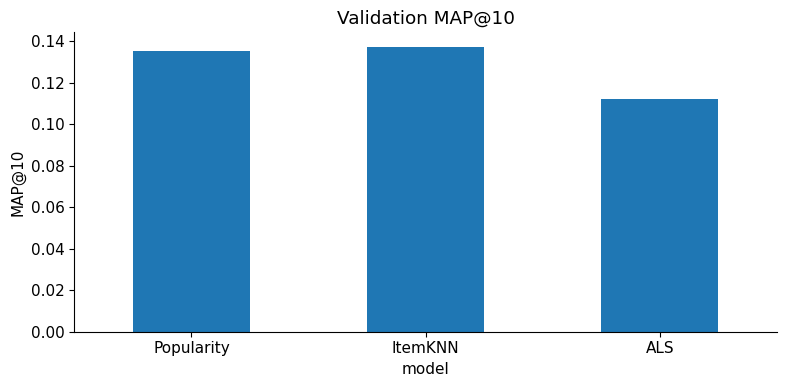

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
comparison["MAP@10"].plot.bar(ax=ax, rot=0)
ax.set(title="Validation MAP@10", ylabel="MAP@10")
plt.tight_layout()
plt.show()

## Латентные факторы

`user_factors` и `item_factors` — обученные матрицы факторов. Обе имеют одинаковую вторую размерность (`factors`). Их скалярное произведение даёт оценку пары пользователь–объект.

In [7]:
print("User factors:", model.model.user_factors.shape)
print("Item factors:", model.model.item_factors.shape)
print("Embedding dimension:", model.factors)

User factors: (850489, 32)
Item factors: (13087, 32)
Embedding dimension: 32


## Оценка на Test

Лучшая конфигурация выбирается только на Validation. После этого ALS и базовые модели обучаются на Train + Validation, и их качество оценивается на одном и том же Test.

In [8]:
test_results = metrics.query(
    "split == 'test' and model in ['Popularity', 'ItemKNN', 'ALS']"
).set_index("model")
display(test_results.drop(columns=["split", "seconds"]).round(4))

,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage,Users
model,,,,,,
Popularity,0.1215,0.2366,0.1598,0.3127,0.0027,106819
ItemKNN,0.1257,0.2487,0.1673,0.3365,0.3462,106819
ALS,0.1012,0.2158,0.1386,0.2949,0.0621,106819


## Анализ по активности пользователей

Cold start и короткая история могут влиять на качество матричной факторизации. Сравнение ниже показывает HitRate@10 на Validation в зависимости от длины истории.

In [9]:
als_recs = model.recommend(validation_targets, k=K)
als_metrics = ranking_metrics(als_recs, validation_targets, model.n_items, k=K)
segments = pd.read_csv(REPORTS / "segments.csv")
activity_comparison = segments.query(
    "split == 'validation' and model in ['ALS', 'ItemKNN']"
)
display(
    activity_comparison.pivot(index="segment", columns="model", values="HitRate@10")
)

model,ALS,ItemKNN
segment,,
1,0.254240,0.326493
2-5,0.223219,0.310112
21+,0.191730,0.226251
6-20,0.198390,0.255471
cold,0.485983,0.485983


## Выводы

Лучшей из трёх конфигураций оказалась ALS с 32 факторами и регуляризацией 0,05. Увеличение размерности до 64 качество не улучшило.

На test MAP@10 составил **0,1012**, ниже Popularity и ItemKNN. На этих данных одной факторизации оказалось недостаточно для хорошей персонализации.

Сохраню ALS среди источников кандидатов: её оценки можно объединить с популярностью и соседями ItemKNN в ранкере.